# Práctica 7. Interferencia y paralelismo cuántico

## Información general

**Asignatura:** Computación cuántica  
**Sesión:** 7  
**Título:** Interferencia y paralelismo cuántico    
**Modalidad:** Individual  
**Entorno recomendado:** Jupyter Notebook  
**Bibliotecas:** NumPy, Matplotlib, Qiskit y Qiskit Aer

## Objetivos

En esta práctica vas a estudiar cómo las fases modifican los resultados de medida mediante interferencia.

Al finalizar la práctica deberás ser capaz de:

- Analizar circuitos sencillos usando amplitudes.
- Comparar circuitos que producen resultados deterministas y probabilísticos.
- Observar interferencia constructiva y destructiva.
- Comprobar cómo una fase puede convertirse en una diferencia de probabilidad.
- Diseñar circuitos que produzcan siempre 0, siempre 1 o una distribución equilibrada.
- Entender el paralelismo cuántico y sus limitaciones.
- Explicar por qué no pueden leerse todas las ramas de una superposición.

## Entrega

Entrega este notebook completado con código ejecutado, resultados visibles, tablas completadas, histogramas y respuestas razonadas.

## 1. Preparación del entorno

Ejecuta la siguiente celda para importar las bibliotecas necesarias.

In [61]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

SEMILLA = 42

## 2. Parte A. Interferencia con NumPy

### Ejercicio 1. Definición de estados y puertas

Define con NumPy:

$$
|0\rangle =
\begin{pmatrix}
1 \\
0
\end{pmatrix}
\qquad
|1\rangle =
\begin{pmatrix}
0 \\
1
\end{pmatrix}
$$

$$
H =
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1 & 1 \\
1 & -1
\end{pmatrix}
$$

$$
X =
\begin{pmatrix}
0 & 1 \\
1 & 0
\end{pmatrix}
\qquad
Y =
\begin{pmatrix}
0 & -i \\
i & 0
\end{pmatrix}
\qquad
Z =
\begin{pmatrix}
1 & 0 \\
0 & -1
\end{pmatrix}
$$

Muestra todas las matrices y comprueba sus dimensiones.

In [62]:
ket_0 = np.array([1, 0], dtype=complex)
ket_1 = np.array([0, 1], dtype=complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

objetos = {"|0>": ket_0, "|1>": ket_1, "H": H, "X": X, "Y": Y, "Z": Z}
for nombre, valor in objetos.items():
    print(nombre)
    print(valor)
    print("shape:", valor.shape)
    print()

|0>
[1.+0.j 0.+0.j]
shape: (2,)

|1>
[0.+0.j 1.+0.j]
shape: (2,)

H
[[ 0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j]]
shape: (2, 2)

X
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
shape: (2, 2)

Y
[[ 0.+0.j -0.-1.j]
 [ 0.+1.j  0.+0.j]]
shape: (2, 2)

Z
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]
shape: (2, 2)



**Responde:**

1. ¿Qué dimensión tienen los estados?
2. ¿Qué dimensión tienen las puertas?
3. ¿Por qué estas puertas pueden actuar sobre un qubit?

Respuesta:

1. Vectores de 2 componentes.
2. Matrices $2\times2$.
3. Son transformaciones sobre vectores de 2 componentes.

### Ejercicio 2. Función de probabilidades

Implementa una función que devuelva las probabilidades de medir 0 y 1 en la base computacional.

In [63]:
def probabilidades(estado):
    """
    Devuelve las probabilidades de medir 0 y 1.
    """
    # TODO: convierte el estado a array complejo
    estado = np.asarray(estado, dtype=complex)

    # TODO: calcula el módulo al cuadrado de cada amplitud
    probs = [abs(estado[0])**2,abs(estado[1])**2]

    return {
        0: float(probs[0]),
        1: float(probs[1]),
    }


print("|0>:", probabilidades(ket_0))
print("|1>:", probabilidades(ket_1))

|0>: {0: 1.0, 1: 0.0}
|1>: {0: 0.0, 1: 1.0}


**Responde:**

1. ¿Por qué se usa el módulo al cuadrado?
2. ¿Pueden las amplitudes ser negativas?
3. ¿Pueden las probabilidades ser negativas?

Respuesta:

1. Por la regla de Born.
2. Sí.
3. No.

## 3. Parte B. Circuitos $HH$ y $HZH$

### Ejercicio 3. Cálculo de $HH|0\rangle$

Calcula con NumPy:

$$
HH|0\rangle
$$

Muestra el estado final, sus probabilidades y desarrolla manualmente el cálculo de amplitudes.

In [64]:
# TODO: calcula HH|0>
estado_hh = H@H@ ket_0

print("HH|0> =", estado_hh)
print("Probabilidades:", probabilidades(estado_hh))

HH|0> = [ 1.00000000e+00+0.j -2.23711432e-17+0.j]
Probabilidades: {0: 0.9999999999999996, 1: 5.004680467665246e-34}


Desarrollo manual:

$$
HH|0\rangle=H|+\rangle=
\frac12\begin{pmatrix}1&1\\1&-1\end{pmatrix}
\begin{pmatrix}1\\1\end{pmatrix}
=\begin{pmatrix}1\\0\end{pmatrix}=|0\rangle.
$$

**Responde:**

1. ¿Qué estado final se obtiene?
2. ¿Qué resultado se obtendrá al medir?
3. ¿Qué amplitud se refuerza?
4. ¿Qué amplitud se cancela?

Respuesta:

1. $|0\rangle$.
2. Siempre 0.
3. La de $|0\rangle$.
4. La de $|1\rangle$.

### Ejercicio 4. Cálculo de $HZH|0\rangle$

Calcula con NumPy:

$$
HZH|0\rangle
$$

Muestra el estado final, sus probabilidades y desarrolla manualmente el cálculo.

In [65]:
# TODO: calcula HZH|0>
estado_hzh = H@Z@H@ket_0

print("HZH|0> =", estado_hzh)
print("Probabilidades:", probabilidades(estado_hzh))

HZH|0> = [-2.23711432e-17+0.j  1.00000000e+00+0.j]
Probabilidades: {0: 5.004680467665246e-34, 1: 0.9999999999999996}


Desarrollo manual:

$$
HZH|0\rangle=H(Z|+\rangle)=H|-\rangle
=\frac12\begin{pmatrix}1&1\\1&-1\end{pmatrix}
\begin{pmatrix}1\\-1\end{pmatrix}
=\begin{pmatrix}0\\1\end{pmatrix}=|1\rangle.
$$

**Responde:**

1. ¿Qué estado se obtiene después de la primera $H$?
2. ¿Qué efecto tiene $Z$ sobre ese estado?
3. ¿Qué estado final se obtiene?
4. ¿Qué resultado se obtendrá al medir?
5. ¿Qué ha cambiado respecto al circuito $HH$?

Respuesta:

1. $|+\rangle$.
2. Lo transforma en $|-\rangle$.
3. $|1\rangle$.
4. Siempre 1.
5. La fase relativa cambia la interferencia.

### Ejercicio 5. Comparación de $HH$ y $HZH$

Completa la tabla:

| Circuito | Estado tras la primera H | Estado antes de medir | P(0) | P(1) | Resultado esperado |
|---|---|---|---:|---:|---|
| $$HH\|0\rangle$$ | $$\|+\rangle$$ | $$\|0\rangle$$ | 1 | 0 | 0 |
| $$HZH\|0\rangle$$ | $$\|+\rangle$$ | $$\|0\rangle$$ | 0 | 1 | 1 |

**Responde:**

1. ¿Por qué una puerta $Z$, que no cambia las probabilidades de $|+\rangle$, cambia el resultado final?
2. ¿Dónde aparece la interferencia constructiva en cada circuito?
3. ¿Dónde aparece la interferencia destructiva?
4. ¿Qué significa convertir fase en probabilidad?

Respuesta:
1. H convierte la fase en probabilidades.
2. HH: en 0; HZH: en 1.
3. HH: en 1; HZH: en 0.
4. Hacer observable una diferencia de fase.

## 4. Parte C. Verificación con Qiskit

### Ejercicio 6. Circuito HH en Qiskit

Construye el circuito `HH` y obtén su vector de estado y probabilidades.

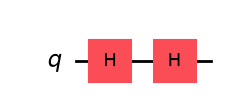

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.9999999999999996)}


In [66]:
# TODO: construye el circuito HH
qc_hh = QuantumCircuit(1)
qc_hh.h(0)
qc_hh.h(0)

estado_qc_hh = Statevector.from_instruction(qc_hh)

display(qc_hh.draw("mpl"))
display(estado_qc_hh.draw("latex"))
print(estado_qc_hh.probabilities_dict())

**Responde:**

1. ¿Coincide con el cálculo hecho con NumPy?
2. ¿Por qué el resultado es determinista?
3. ¿Qué papel tiene la segunda Hadamard?

Respuesta:

1. Sí.
2. La probabilidad de 0 es 1.
3. Deshace la primera H.

### Ejercicio 7. Circuito HZH en Qiskit

Construye el circuito `HZH` y obtén su vector de estado y probabilidades.

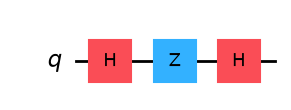

<IPython.core.display.Latex object>

{np.str_('1'): np.float64(0.9999999999999996)}


In [67]:
# TODO: construye el circuito HZH
qc_hzh = QuantumCircuit(1)
qc_hzh.h(0)
qc_hzh.z(0)
qc_hzh.h(0)

estado_qc_hzh = Statevector.from_instruction(qc_hzh)

display(qc_hzh.draw("mpl"))
display(estado_qc_hzh.draw("latex"))
print(estado_qc_hzh.probabilities_dict())

**Responde:**

1. ¿Coincide con el cálculo hecho con NumPy?
2. ¿Qué papel tiene la puerta Z?
3. ¿Por qué este circuito produce siempre 1?

Respuesta:

1. Sí.
2. Invierte la fase de $|1\rangle$.
3. La interferencia elimina la amplitud de 0.

### Ejercicio 8. Medida de ambos circuitos

Añade medida a ambos circuitos y ejecútalos con `shots = 1000`.

In [68]:
def ejecutar_con_medida(qc_sin_medida, shots=1000, semilla=SEMILLA):

    n = qc_sin_medida.num_qubits
    # TODO: crea un circuito nuevo con el mismo número de qubits y bits clásicos
    qc = QuantumCircuit(n,n)

    # TODO: copia las instrucciones del circuito sin medida
    #instrucciones=qc_sin_medida.get_instructions()
    #i = 0
    #for instruccion in instrucciones:
    #    qc.instruccion(i)
    #    i=i+1

    qc.compose(qc_sin_medida, qubits=range(n), inplace=True)
    # TODO: mide todos los qubits
    qc.measure(range(n), range(n))

    # Otra manera de hacerlo qc = qc_sin_medida.copy()
    # qc.measure_all()
    simulador = AerSimulator(seed_simulator=semilla)
    qc_t = transpile(qc, simulador)
    resultado = simulador.run(qc_t, shots=shots).result()
    return qc, resultado.get_counts()


shots = 1000



qc_hh_medido, conteos_hh = ejecutar_con_medida(qc_hh, shots=shots)
qc_hzh_medido, conteos_hzh = ejecutar_con_medida(qc_hzh, shots=shots)

print("HH:", conteos_hh)
print("HZH:", conteos_hzh)

HH: {'0': 1000}
HZH: {'1': 1000}


Completa la tabla:

| Circuito | Conteos esperados | Conteos obtenidos |
|---|---|---|
| $HH\|0\rangle$ | 100 % de 0 | `{'0': 1000}` |
| $HZH\|0\rangle$ | 100 % de 1 | `{'1': 1000}` |

**Responde:**

1. ¿Son exactamente deterministas los resultados?
2. ¿Por qué no aparece variabilidad estadística en estos dos casos ideales?
3. ¿Qué diferencia habría si el estado final fuese $|+\rangle$?

Respuesta:

1. Sí, en simulación ideal.
2. El estado final es un estado base.
3. Habría variación alrededor del 50 %.

## 5. Parte D. Otras puertas entre Hadamard

### Ejercicio 9. Circuitos $HXH$, $HYH$, $HZH$

Construye y analiza los circuitos:

$$
HXH|0\rangle,\qquad HYH|0\rangle,\qquad HZH|0\rangle
$$

HXH


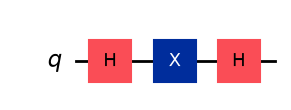

<IPython.core.display.Latex object>

Probabilidades: {np.str_('0'): np.float64(0.9999999999999996)}
Conteos: {'0': 1000}

HYH


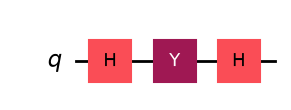

<IPython.core.display.Latex object>

Probabilidades: {np.str_('1'): np.float64(0.9999999999999996)}
Conteos: {'1': 1000}

HZH


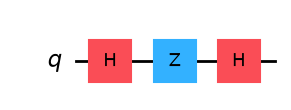

<IPython.core.display.Latex object>

Probabilidades: {np.str_('1'): np.float64(0.9999999999999996)}
Conteos: {'1': 1000}



In [69]:
def circuito_huh(nombre_puerta):
    qc = QuantumCircuit(1)
    qc.h(0)
    puerta = nombre_puerta.lower()
    if puerta not in ("x", "y", "z"):
        raise ValueError("La puerta debe ser X, Y o Z")
    getattr(qc, puerta)(0)
    qc.h(0)
    return qc

circuitos_huh = {
    "HXH": circuito_huh("x"),
    "HYH": circuito_huh("y"),
    "HZH": circuito_huh("z"),
}
resultados_huh = {}
for nombre, qc in circuitos_huh.items():
    print(nombre)
    estado = Statevector.from_instruction(qc)
    probs = estado.probabilities_dict()
    _, conteos = ejecutar_con_medida(qc, shots=1000)
    resultados_huh[nombre] = {"estado": estado, "probs": probs, "conteos": conteos}
    display(qc.draw("mpl"))
    display(estado.draw("latex"))
    print("Probabilidades:", probs)
    print("Conteos:", conteos)
    print()

Completa la tabla:

| Circuito | Estado final | P(0) | P(1) | Resultado dominante |
|---|---|---:|---:|---|
| $HXH\|0\rangle$ | $\|0\rangle$ | 1 | 0 | 0 |
| $HYH\|0\rangle$ | $-i\|1\rangle$ | 0 | 1 | 1 |
| $HZH\|0\rangle$ | $\|1\rangle$ | 0 | 1 | 1 |

**Responde:**

1. ¿Qué circuito produce siempre 0?
2. ¿Qué circuitos producen siempre 1?
3. ¿Aparecen fases globales en alguno de los resultados?
4. ¿Se pueden detectar las fases globales midiendo en la base computacional?
5. ¿Qué relación se observa entre $HZH$ y $X$?

Respuesta:
1. HXH.
2. HYH y HZH.
3. Sí, en HYH ($-i$).
4. No.
5. $HZH=X$.

### Ejercicio 10. Comprobación matricial de $HZH = X$

Calcula con NumPy:

$$
HZH
$$

y compáralo con:

$$
X
$$

In [70]:
HZH = H @ Z @ H
HXH = H @ X @ H
print("HZH =\n", HZH)
print("X =\n", X)
print("¿HZH = X?", np.allclose(HZH, X))
print()
print("HXH =\n", HXH)
print("Z =\n", Z)
print("¿HXH = Z?", np.allclose(HXH, Z))

HZH =
 [[-2.23711432e-17+0.j  1.00000000e+00+0.j]
 [ 1.00000000e+00+0.j -2.23711432e-17+0.j]]
X =
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
¿HZH = X? True

HXH =
 [[ 1.00000000e+00+0.j -2.23711432e-17+0.j]
 [ 2.23711432e-17+0.j -1.00000000e+00+0.j]]
Z =
 [[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]
¿HXH = Z? True


**Responde:**

1. ¿Se cumple exactamente $HZH=X$?
2. ¿Qué significa esta igualdad a nivel de circuitos?
3. ¿Por qué Hadamard puede interpretarse como un cambio de base?
4. ¿Qué ocurre con $HXH$?

Respuesta:

1. Sí, salvo redondeo numérico.
2. Son operaciones equivalentes.
3. Intercambia los ejes X y Z.
4. $HXH=Z$.

## 6. Parte E. Diseñar circuitos

### Ejercicio 11. Circuito que produzca siempre 0

Diseña al menos dos circuitos distintos que, partiendo de $|0\rangle$, produzcan siempre 0 al medir.

Circuito 0A


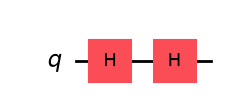

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.9999999999999996)}

Circuito 0B


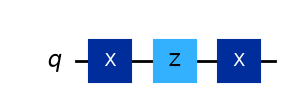

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(1.0)}



In [71]:
circuitos_siempre_0 = []

qc0_a = QuantumCircuit(1)
qc0_a.h(0)
qc0_a.h(0)
circuitos_siempre_0.append(("Circuito 0A", qc0_a))

qc0_b = QuantumCircuit(1)
qc0_b.x(0)
qc0_b.z(0)
qc0_b.x(0)
circuitos_siempre_0.append(("Circuito 0B", qc0_b))

for nombre, qc in circuitos_siempre_0:
    print(nombre)
    estado = Statevector.from_instruction(qc)
    display(qc.draw("mpl"))
    display(estado.draw("latex"))
    print(estado.probabilities_dict())
    print()

**Responde:**

1. ¿Qué tienen en común los estados finales?
2. ¿Puede haber fases globales y seguir midiendo siempre 0?

Respuesta:

1. Son $e^{i\phi}|0\rangle$.
2. Sí.

### Ejercicio 12. Circuito que produzca siempre 1

Diseña al menos dos circuitos distintos que, partiendo de $|0\rangle$, produzcan siempre 1 al medir.

Circuito 1A


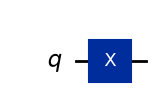

<IPython.core.display.Latex object>

{np.str_('1'): np.float64(1.0)}

Circuito 1B


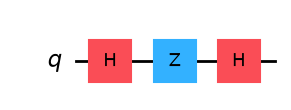

<IPython.core.display.Latex object>

{np.str_('1'): np.float64(0.9999999999999996)}



In [72]:
circuitos_siempre_1 = []

qc1_a = QuantumCircuit(1)
qc1_a.x(0)
circuitos_siempre_1.append(("Circuito 1A", qc1_a))

qc1_b = QuantumCircuit(1)
qc1_b.h(0)
qc1_b.z(0)
qc1_b.h(0)
circuitos_siempre_1.append(("Circuito 1B", qc1_b))

for nombre, qc in circuitos_siempre_1:
    print(nombre)
    estado = Statevector.from_instruction(qc)
    display(qc.draw("mpl"))
    display(estado.draw("latex"))
    print(estado.probabilities_dict())
    print()

**Responde:**

1. ¿Qué estado final deben producir estos circuitos?
2. ¿Importa que el estado final sea $-|1\rangle$ o $i|1\rangle$?
3. ¿Por qué?

Respuesta:

1. $e^{i\phi}|1\rangle$.
2. No.
3. La fase global no cambia probabilidades.

### Ejercicio 13. Circuito con distribución equilibrada

Diseña al menos dos circuitos que produzcan:

$$
P(0)=P(1)=\frac{1}{2}
$$

Equilibrado A


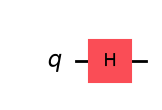

<IPython.core.display.Latex object>

Probabilidades: {np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
Conteos: {'0': 514, '1': 486}


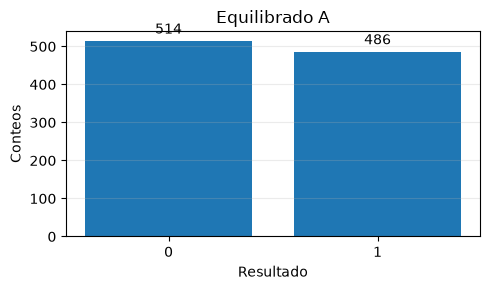

Equilibrado B


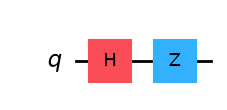

<IPython.core.display.Latex object>

Probabilidades: {np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
Conteos: {'0': 514, '1': 486}


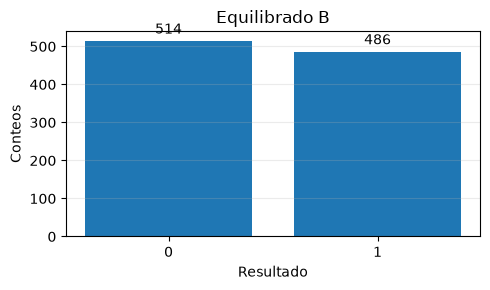

In [73]:
circuitos_equilibrados = []

qce_a = QuantumCircuit(1)
qce_a.h(0)
circuitos_equilibrados.append(("Equilibrado A", qce_a))

qce_b = QuantumCircuit(1)
qce_b.h(0)
qce_b.z(0)
circuitos_equilibrados.append(("Equilibrado B", qce_b))

for nombre, qc in circuitos_equilibrados:
    print(nombre)
    estado = Statevector.from_instruction(qc)
    _, conteos = ejecutar_con_medida(qc, shots=1000)
    display(qc.draw("mpl"))
    display(estado.draw("latex"))
    print("Probabilidades:", estado.probabilities_dict())
    print("Conteos:", conteos)
    etiquetas = ["0", "1"]
    valores = [conteos.get(k, 0) for k in etiquetas]
    fig, ax = plt.subplots(figsize=(5, 3))
    barras = ax.bar(etiquetas, valores)
    ax.bar_label(barras, padding=3)
    ax.set_title(nombre)
    ax.set_xlabel("Resultado")
    ax.set_ylabel("Conteos")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

**Responde:**

1. ¿Los conteos son exactamente 50 % y 50 %?
2. ¿Qué diferencia hay entre probabilidad teórica y frecuencia observada?
3. ¿Pueden dos estados distintos producir la misma distribución equilibrada?

Respuesta:

1. No necesariamente.
2. La probabilidad es teórica; la frecuencia es experimental.
3. Sí, por ejemplo $|+\rangle$ y $|-\rangle$.

## 7. Parte F. Fase y probabilidad

### Ejercicio 14. Estados con la misma distribución

Considera:

$$
|+\rangle =
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

$$
|-\rangle =
\frac{|0\rangle - |1\rangle}{\sqrt{2}}
$$

$$
|+i\rangle =
\frac{|0\rangle + i|1\rangle}{\sqrt{2}}
$$

Define los tres estados con NumPy y calcula sus probabilidades.

In [74]:
ket_plus = (ket_0 + ket_1) / np.sqrt(2)
ket_minus = (ket_0 - ket_1) / np.sqrt(2)
ket_plus_i = (ket_0 + 1j * ket_1) / np.sqrt(2)
estados_fase = {"|+>": ket_plus, "|->": ket_minus, "|+i>": ket_plus_i}
for nombre, estado in estados_fase.items():
    print(nombre)
    print("estado:", estado)
    print("probabilidades:", probabilidades(estado))
    print()

|+>
estado: [0.70710678+0.j 0.70710678+0.j]
probabilidades: {0: 0.4999999999999999, 1: 0.4999999999999999}

|->
estado: [ 0.70710678+0.j -0.70710678+0.j]
probabilidades: {0: 0.4999999999999999, 1: 0.4999999999999999}

|+i>
estado: [0.70710678+0.j         0.        +0.70710678j]
probabilidades: {0: 0.4999999999999999, 1: 0.4999999999999999}



Completa:

| Estado | Amplitud de $\|0\rangle$ | Amplitud de $\|1\rangle$ | P(0) | P(1) |
|---|---|---|---:|---:|
| $\|+\rangle$ | 1/sqrt(2)  | 1/sqrt(2) | 0.5 | 0.5 |
| $\|-\rangle$ | 1/sqrt(2) | -1/sqrt(2) | 0.5 | 0.5 |
| $\|+i\rangle$ | 1/sqrt(2) | i/sqrt(2) | 0.5 | 0.5 |

**Responde:**

1. ¿Tienen la misma distribución de medida en la base computacional?
2. ¿Son el mismo estado?
3. ¿Qué información no aparece en las probabilidades?
4. ¿Qué operación puede transformar diferencias de fase en diferencias de probabilidad?

Respuesta:
1. Sí.
2. No.
3. La fase relativa.
4. Hadamard (combinada con cambios de fase).

### Ejercicio 15. Distinguir $|+\rangle$ y $|-\rangle$

Diseña un procedimiento para distinguir $|+\rangle$ y $|-\rangle$. Pista: antes de medir, aplica una puerta Hadamard.

In [75]:
qc_plus = QuantumCircuit(1)
qc_plus.h(0)        # Preparar |+>
qc_plus.h(0)        # Cambiar a la base Z

qc_minus = QuantumCircuit(1)
qc_minus.h(0)       # Preparar |+>
qc_minus.z(0)       # Preparar |->
qc_minus.h(0)       # Cambiar a la base Z

_, conteos_plus = ejecutar_con_medida(qc_plus, shots=1000)
_, conteos_minus = ejecutar_con_medida(qc_minus, shots=1000)
print("|+>:", conteos_plus)
print("|->:", conteos_minus)

|+>: {'0': 1000}
|->: {'1': 1000}


Completa la tabla:

| Estado preparado | Operación antes de medir | Resultado esperado |
|---|---|---|
| $\|+\rangle$ | H | 0(100 %) |
| $\|-\rangle$ | H | 1(100 %) |

**Responde:**

1. ¿Por qué medir directamente no permite distinguirlos de forma determinista?
2. ¿Por qué aplicar $H$ antes de medir sí permite distinguirlos?
3. ¿Qué demuestra este ejercicio sobre la fase relativa?

Respuesta:

1. Ambos dan 50 % de cada resultado.
2. H los convierte en $|0\rangle$ y $|1\rangle$.
3. La fase relativa puede hacerse observable.

## 8. Parte G. Paralelismo cuántico

### Ejercicio 16. Superposición de varios qubits

Construye un circuito de tres qubits con Hadamard en todos ellos.

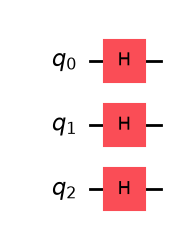

<IPython.core.display.Latex object>

{np.str_('000'): np.float64(0.12499999999999994), np.str_('001'): np.float64(0.12499999999999994), np.str_('010'): np.float64(0.12499999999999994), np.str_('011'): np.float64(0.12499999999999994), np.str_('100'): np.float64(0.12499999999999994), np.str_('101'): np.float64(0.12499999999999994), np.str_('110'): np.float64(0.12499999999999994), np.str_('111'): np.float64(0.12499999999999994)}
Número de estados con probabilidad no nula: 8


In [76]:
qc_3 = QuantumCircuit(3)
for q in range(3):
    qc_3.h(q)
estado_3 = Statevector.from_instruction(qc_3)
probs_3 = estado_3.probabilities_dict()
display(qc_3.draw("mpl"))
display(estado_3.draw("latex"))
print(probs_3)
print("Número de estados con probabilidad no nula:", len(probs_3))

**Responde:**

1. ¿Cuántas ramas aparecen en la superposición?
2. ¿Qué probabilidad tiene cada rama?
3. ¿Qué ocurre si medimos el circuito?
4. ¿Obtenemos todas las ramas o solo una?

Respuesta:

1. Ocho.
2. $1/8$.
3. Sale una de las ocho cadenas.
4. Solo una por ejecución.

### Ejercicio 17. Medida de una superposición de tres qubits

Añade tres bits clásicos, mide los tres qubits y ejecuta con `shots = 1000`. Representa los resultados en un histograma.

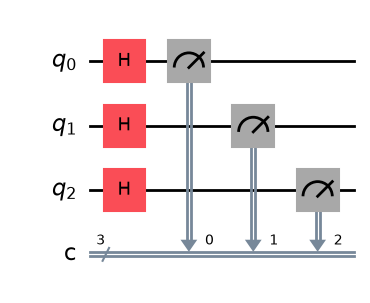

{'000': 107, '010': 136, '011': 121, '101': 127, '100': 123, '111': 134, '110': 115, '001': 137}


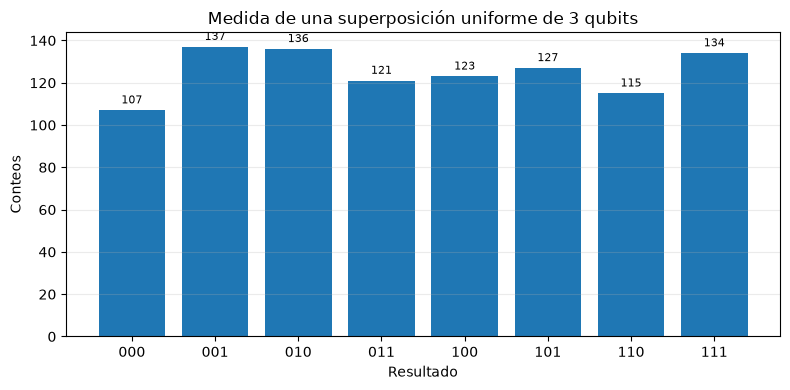

In [77]:
qc_3_medida = QuantumCircuit(3, 3)
for q in range(3):
    qc_3_medida.h(q)
qc_3_medida.measure(range(3), range(3))

simulador = AerSimulator(seed_simulator=SEMILLA)
qc_t = transpile(qc_3_medida, simulador)
resultado = simulador.run(qc_t, shots=1000).result()
conteos_3 = resultado.get_counts()
display(qc_3_medida.draw("mpl"))
print(conteos_3)

etiquetas = [format(i, "03b") for i in range(8)]
valores = [conteos_3.get(k, 0) for k in etiquetas]
fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(etiquetas, valores)
ax.bar_label(barras, padding=3, fontsize=8)
ax.set_title("Medida de una superposición uniforme de 3 qubits")
ax.set_xlabel("Resultado")
ax.set_ylabel("Conteos")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**Responde:**

1. ¿Aparecen todos los estados posibles?
2. ¿Aparecen todos el mismo número exacto de veces?
3. ¿Qué se espera teóricamente?
4. ¿Por qué esto no significa que podamos leer todas las ramas de la superposición en una sola ejecución?

Respuesta:

1. Sí, normalmente.
2. No.
3. $1/8$ por estado.
4. Una ejecución devuelve una sola cadena.

### Ejercicio 18. Evaluación simultánea de una operación

Considera la puerta $X$, que transforma:

$$
|0\rangle \rightarrow |1\rangle
\qquad
|1\rangle \rightarrow |0\rangle
$$

Prepara el estado:

$$
|+\rangle =
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

y aplica $X$. Calcula:

$$
X|+\rangle
$$

X|+> = [0.70710678+0.j 0.70710678+0.j]
Probabilidades: {0: 0.4999999999999999, 1: 0.4999999999999999}


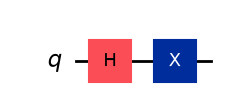

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [78]:
estado_x_plus = X @ ket_plus
print("X|+> =", estado_x_plus)
print("Probabilidades:", probabilidades(estado_x_plus))

qc_x_plus = QuantumCircuit(1)
qc_x_plus.h(0)
qc_x_plus.x(0)
estado_qc_x_plus = Statevector.from_instruction(qc_x_plus)
display(qc_x_plus.draw("mpl"))
display(estado_qc_x_plus.draw("latex"))
print(estado_qc_x_plus.probabilities_dict())

**Responde:**

1. ¿Qué efecto tiene $X$ sobre cada componente de la superposición?
2. ¿Qué estado final se obtiene?
3. ¿Ha cambiado la distribución de probabilidad?
4. ¿Por qué este ejemplo ilustra la linealidad de las operaciones cuánticas?

Respuesta:

1. Intercambia $|0\rangle$ y $|1\rangle$.
2. $|+\rangle$.
3. No.
4. X actúa por separado en cada amplitud.

## 9. Reto avanzado

### Ejercicio 19. Diseñar un circuito con interferencia controlada

Diseña tres circuitos de un qubit que partan de $|0\rangle$ y produzcan:

1. Resultado siempre 0.
2. Resultado siempre 1.
3. Distribución equilibrada.

Condiciones:

- Al menos uno debe usar una puerta $Z$.
- Al menos uno debe usar dos puertas Hadamard.
- Al menos uno debe usar una fase que no sea visible directamente en una medida intermedia.

Para cada circuito:

- Dibuja el circuito.
- Obtén el estado final.
- Obtén las probabilidades.
- Ejecuta 1000 shots.
- Explica el resultado usando amplitudes e interferencia.

Siempre 0


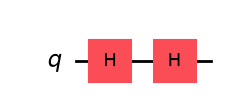

<IPython.core.display.Latex object>

Probabilidades: {np.str_('0'): np.float64(0.9999999999999996)}
Conteos: {'0': 1000}

Siempre 1


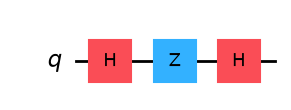

<IPython.core.display.Latex object>

Probabilidades: {np.str_('1'): np.float64(0.9999999999999996)}
Conteos: {'1': 1000}

Equilibrado


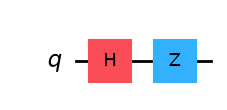

<IPython.core.display.Latex object>

Probabilidades: {np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
Conteos: {'0': 514, '1': 486}



In [79]:
reto_circuitos = []

qc_reto_0 = QuantumCircuit(1)
qc_reto_0.h(0)
qc_reto_0.h(0)
reto_circuitos.append(("Siempre 0", qc_reto_0))

qc_reto_1 = QuantumCircuit(1)
qc_reto_1.h(0)
qc_reto_1.z(0)
qc_reto_1.h(0)
reto_circuitos.append(("Siempre 1", qc_reto_1))

qc_reto_eq = QuantumCircuit(1)
qc_reto_eq.h(0)
qc_reto_eq.z(0)
reto_circuitos.append(("Equilibrado", qc_reto_eq))

for nombre, qc in reto_circuitos:
    print(nombre)
    estado = Statevector.from_instruction(qc)
    _, conteos = ejecutar_con_medida(qc, shots=1000)
    display(qc.draw("mpl"))
    display(estado.draw("latex"))
    print("Probabilidades:", estado.probabilities_dict())
    print("Conteos:", conteos)
    print()

Explicación del reto:

Respuesta: 
$HH$ refuerza la amplitud de 0; $HZH$ refuerza la de 1. $HZ$ deja $|-\rangle$: fase relativa invisible en la medida Z y resultados equilibrados.

## 10. Pruebas mínimas

Incluye al final del notebook las siguientes pruebas. Deben ejecutarse sin errores cuando la práctica esté completada correctamente.

In [80]:
assert np.allclose(H @ H @ ket_0, ket_0)
estado_hzh = H @ Z @ H @ ket_0
assert np.allclose(estado_hzh, ket_1)
HZH = H @ Z @ H
assert np.allclose(HZH, X)
HXH = H @ X @ H
assert np.allclose(HXH, Z)
probs_hh = probabilidades(H @ H @ ket_0)
assert np.isclose(probs_hh[0], 1.0)
assert np.isclose(probs_hh[1], 0.0)
probs_hzh = probabilidades(H @ Z @ H @ ket_0)
assert np.isclose(probs_hzh[0], 0.0)
assert np.isclose(probs_hzh[1], 1.0)

# Prueba propia: distribución equilibrada de |->
assert np.allclose(list(probabilidades(ket_minus).values()), [0.5, 0.5])